# Disorder-averaged overlap distributions at $h=0.15$

**Chosen longitudinal field: $h=0.15$, fixed for every exact and Monte Carlo
result in this notebook.** The transverse field $\Gamma$ takes values 0.60 and
0.65; $h$ is held fixed as $\Gamma$ changes.

**Scan update:** the figures below preserve the dated $\Gamma=0.60,0.65$
measurements. The requested scan uses $\Gamma=0.55,0.56,\ldots,0.70$ for
$L=4$, and $\Gamma=0.55,0.56,\ldots,0.60$ for $L=6$,
with $\Delta\Gamma=0.01$ at the same fixed
$h=0.15$, to measure how the distribution width changes. Those pending data
are not included in these snapshot curves.

The wider search tests a possible shift toward larger $\Gamma$ as $L$ increases
at fixed $h$. The original $L=6$ campaign also covers $\Gamma=0.60,0.65,0.70,0.85,1.00$;
its low-field fine grid is only a supplement. Higher-field coverage will bracket
any candidate glassy regime before refining the relevant interval. The direction
of the shift and the existence of glassy order remain to be established from
matched disorder averages and connected correlations.

**Hamiltonian and two-body disorder.** Periodic kagome nearest-neighbor bonds
are generated once per disorder sample, with
$$H=\sum_{\langle ij\rangle}K_{ij}Z_iZ_j-h\sum_i Z_i-\Gamma\sum_i X_i,
\qquad K_{ij}=1+0.5u_{ij},\quad u_{ij}\overset{\mathrm{iid}}\sim U(-1,1).$$
Thus $K_{ij}\sim U(0.5,1.5)$, independently on each undirected nearest-neighbor
edge; all bonds are antiferromagnetic and their mean strength sets the energy
unit. Frustration comes from kagome geometry. The implementation stores
$J_{ij}=-K_{ij}$ in the equivalent convention $-\sum J_{ij}Z_iZ_j$.
For reproducibility, NumPy `default_rng(SeedSequence([20261027, L, sample_id, 1]))`
draws one uniform variate per bond in the lattice bond-list order; the final
`1` specifies periodic boundaries. These are quenched couplings: the same bonds
are held fixed through training, MC and projection, across both guide families,
all seeds and every $\Gamma$ for a given $(L,\mathrm{sample\_id})$.
$L=2$ uses IDs 50000–50007 and $L=4$ uses 60000–60007. Different sizes have
different bond realizations, even if an ID is reused. Couplings are never
selected or reweighted by the observed shape of $P(q)$.

Only disorder averages are shown at $\Gamma=0.60,0.65$. The $L=2$ panels overlay
exact guide, exact ground-state, and available MC/GFMC curves; $L=4$ uses
**before projection** and **after projection** columns.
Each curve gives equal weight to eight disorders.
**Capped error bars are $\pm1$ standard error of the disorder mean**
($s_J/\sqrt{8}$), pointwise in $q$. They describe finite-ensemble variation and
do not bound mixing, finite-population or finite-forward-time errors.

$q=N^{-1}\sum_i s_i t_i$ uses independent physical replicas of the same disorder.
$P(q)$ is probability mass per allowed overlap; connecting lines are visual aids.
There are two figures: $L=2$ with exact and Monte Carlo comparisons, and $L=4$.
All outputs were computed and executed on AutoDL.

In [1]:
%matplotlib inline
from pathlib import Path
import hashlib, json
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
root=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'data/kagome').is_dir())
folder=root/'data/kagome/ltfim_disorder_scaling_v1/notebook_snapshot/20261103T031619Z_compact_complete'
load=lambda name: json.loads((folder/name).read_text())
guides=load('guide_distributions.json')['rows']
l2=load('guide_distributions_l2.json')['rows']
projected=load('projected_distributions.json')['rows']
exact=load('exact_l2_reference.json')['rows']
if (folder/'interim_snapshot.json').exists():
    frozen=load('interim_snapshot.json')
    for name,digest in frozen['input_sha256'].items():
        assert hashlib.sha256((folder/name).read_bytes()).hexdigest()==digest
    print('Histogram inputs frozen at:',frozen['created_utc'])
assert load('manifest.json')['h']==.15
assert all(r['h']==.15 for r in exact)
allow_pending=False
if not allow_pending:
    complete=load('histogram_complete.json')
    assert complete['projected']==128 and complete['sampled']==32 and not complete['failures']
    assert len(projected)==128 and len(l2)==32
assert all(r['replay_verified'] for r in projected if r['task']['L']==4)
figures=folder/'figures'; figures.mkdir(exist_ok=True)
colors={'jastrow':'tab:blue','rbm_2':'tab:orange'}
names={'jastrow':'Jastrow','rbm_2':'RBM (alpha=2)'}
def mean_se(values):
    a=np.asarray(values,dtype=float)
    assert len(a)==8
    np.testing.assert_allclose(a.sum(1),1,atol=1e-12)
    return a.mean(0),a.std(0,ddof=1)/np.sqrt(len(a))
def curve(ax,q,values,label,color,fmt='o-',alpha=1):
    if q is None:
        ax.text(.03,.96-.065*len(ax.texts),label+' pending (complete ensemble required)',
                transform=ax.transAxes,va='top',fontsize=7,color=color)
        return
    mean,se=mean_se(values)
    ax.errorbar(q,mean,yerr=se,fmt=fmt,color=color,ms=3,lw=1.15,
                elinewidth=.75,capsize=2,capthick=.75,label=label,alpha=alpha)
def guide_group(rows,L,g,kind):
    group=[r for r in rows if r['task']['L']==L and r['task']['gamma']==g
           and r['task']['kind']==kind and r.get('selected',True)]
    group=sorted(group,key=lambda r:r['task']['sample_id'])
    if allow_pending and len(group)!=8:
        return None,None
    assert len(group)==8 and len({r['task']['sample_id'] for r in group})==8
    return np.array(group[0]['q_grid']),np.array([np.mean([s['mass'] for s in r['starts']],axis=0) for r in group])
def projected_group(L,g,kind):
    group=[r for r in projected if (r['task']['L'],r['task']['gamma'],r['task']['kind'])==(L,g,kind)]
    ids=sorted({r['task']['sample_id'] for r in group})
    if allow_pending and (len(group)!=16 or len(ids)!=8):
        return None,None
    assert len(group)==16 and len(ids)==8
    values=[]
    for sid in ids:
        rs=[r for r in group if r['task']['sample_id']==sid]
        assert {r['task']['repeat'] for r in rs}=={0,1}
        values.append(np.mean([r['mass'] for r in rs],axis=0))
    return np.array(group[0]['q_grid']),np.array(values)
def finish(fig,name):
    fig.tight_layout()
    fig.savefig(figures/(name+'.png'),dpi=180,bbox_inches='tight')
    fig.savefig(figures/(name+'.pdf'),bbox_inches='tight')
    plt.show()
def axes_style(axes):
    for ax in axes.flat:
        ax.set(xlabel='q',ylabel='Disorder mean P(q) mass',xlim=(-1.03,1.03))
        ax.grid(alpha=.2); ax.legend(fontsize=8)
print('Frozen L=4 production snapshot:',load('snapshot.json')['created_utc'])
print('Chosen longitudinal field: h=0.15 (fixed); transverse fields: Gamma=0.60, 0.65.')
print(f'Completed histogram measurements: {len(projected)}/128 GFMC runs and {len(l2)}/32 L=2 guide MC tasks; eight disorders per plotted curve.')
for L in [2,4]:
    for g in [.6,.65]:
        for kind in ['jastrow','rbm_2']:
            before=guide_group(l2 if L==2 else guides,L,g,kind)[0] is not None
            after=projected_group(L,g,kind)[0] is not None
            print(f'L={L}, Gamma={g:.2f}, {names[kind]}: before MC {"complete" if before else "pending"}; after GFMC {"complete" if after else "pending"}')


Histogram inputs frozen at: 20261103T031619Z
Frozen L=4 production snapshot: 20261103T021444Z
Chosen longitudinal field: h=0.15 (fixed); transverse fields: Gamma=0.60, 0.65.
Completed histogram measurements: 128/128 GFMC runs and 32/32 L=2 guide MC tasks; eight disorders per plotted curve.
L=2, Gamma=0.60, Jastrow: before MC complete; after GFMC complete
L=2, Gamma=0.60, RBM (alpha=2): before MC complete; after GFMC complete
L=2, Gamma=0.65, Jastrow: before MC complete; after GFMC complete
L=2, Gamma=0.65, RBM (alpha=2): before MC complete; after GFMC complete
L=4, Gamma=0.60, Jastrow: before MC complete; after GFMC complete
L=4, Gamma=0.60, RBM (alpha=2): before MC complete; after GFMC complete
L=4, Gamma=0.65, Jastrow: before MC complete; after GFMC complete
L=4, Gamma=0.65, RBM (alpha=2): before MC complete; after GFMC complete


**$L=2$: all comparisons on the same axes.** Each panel overlays exact
enumeration of the trained Jastrow and RBM guide distributions (colored dashed
curves with triangle markers), the exact ground-state distribution (black squares),
and available guide MCMC (colored dots without connecting lines) and pure GFMC
estimates (colored solid curves with circles). One panel is shown per $\Gamma$.
All curves use disorder IDs 50000–50007. The two guide families use their
previously selected energy-trained fits. MC starts and repeats are averaged
within each disorder before computing the disorder mean and its error bars.

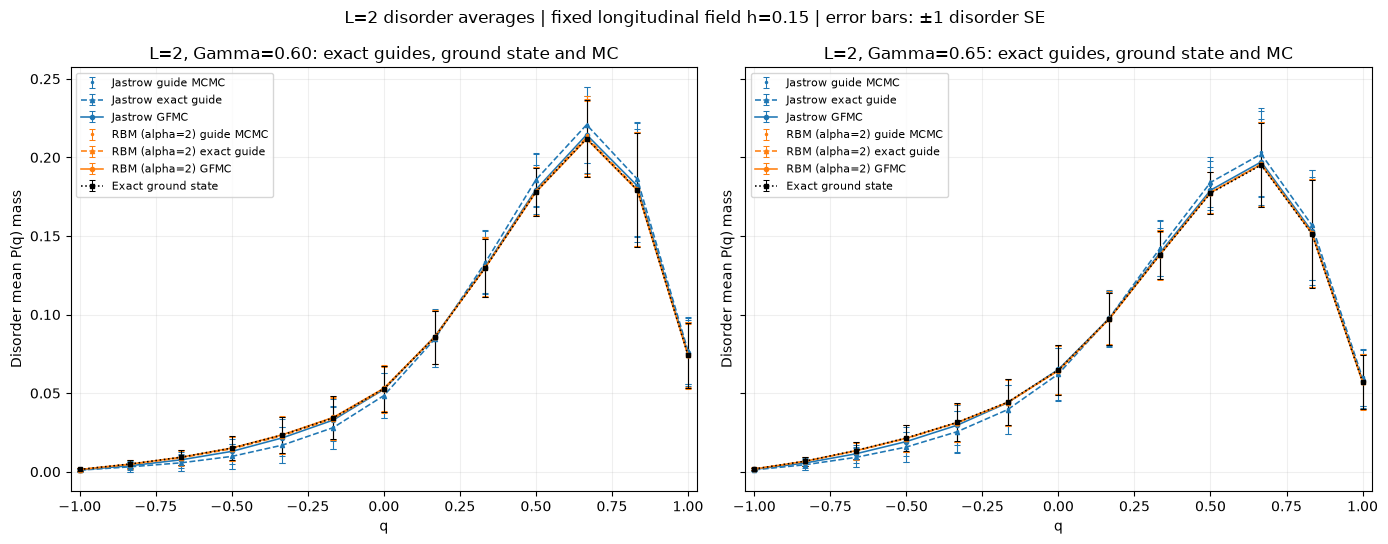

In [2]:
fig,axes=plt.subplots(1,2,figsize=(14,5.5),sharex=True,sharey=True)
for ax,g in zip(axes,[.6,.65]):
    reference=sorted([r for r in exact if r['gamma']==g and r['sample_id'] in range(50000,50008)],key=lambda r:r['sample_id'])
    assert [r['sample_id'] for r in reference]==list(range(50000,50008))
    q=np.array(reference[0]['exact']['q'])
    for kind in ['jastrow','rbm_2']:
        grid,values=guide_group(l2,2,g,kind)
        curve(ax,grid,values,names[kind]+' guide MCMC',colors[kind],fmt='.')
        enumerated=[next(f['pq'] for f in r['fits'] if f['kind']==kind and f['selected']) for r in reference]
        curve(ax,q,enumerated,names[kind]+' exact guide',colors[kind],fmt='^--')
        grid,values=projected_group(2,g,kind)
        curve(ax,grid,values,names[kind]+' GFMC',colors[kind])
    curve(ax,q,[r['exact']['pq'] for r in reference],'Exact ground state','black',fmt='s:')
    ax.set_title(f'L=2, Gamma={g:.2f}: exact guides, ground state and MC')
axes_style(axes)
fig.suptitle('L=2 disorder averages | fixed longitudinal field h=0.15 | error bars: ±1 disorder SE',fontsize=12)
finish(fig,'disorder_mean_l2_overlay')


**$L=4$: before and after projection.** Both columns use disorder IDs
60000–60007 and the same selected frozen guides. Before projection uses MCMC
with random/up/down starts. After projection uses four independently branching
populations with descendant-weighted tagged configurations, 512 walkers per
population, equilibration and forward times 16, eight cycles and two repeats.
The histograms replay the frozen production trajectories; their first and
second moments and connected spectra match those original records to $10^{-12}$.
The $L=2$ and $L=4$ disorder ensembles are different.

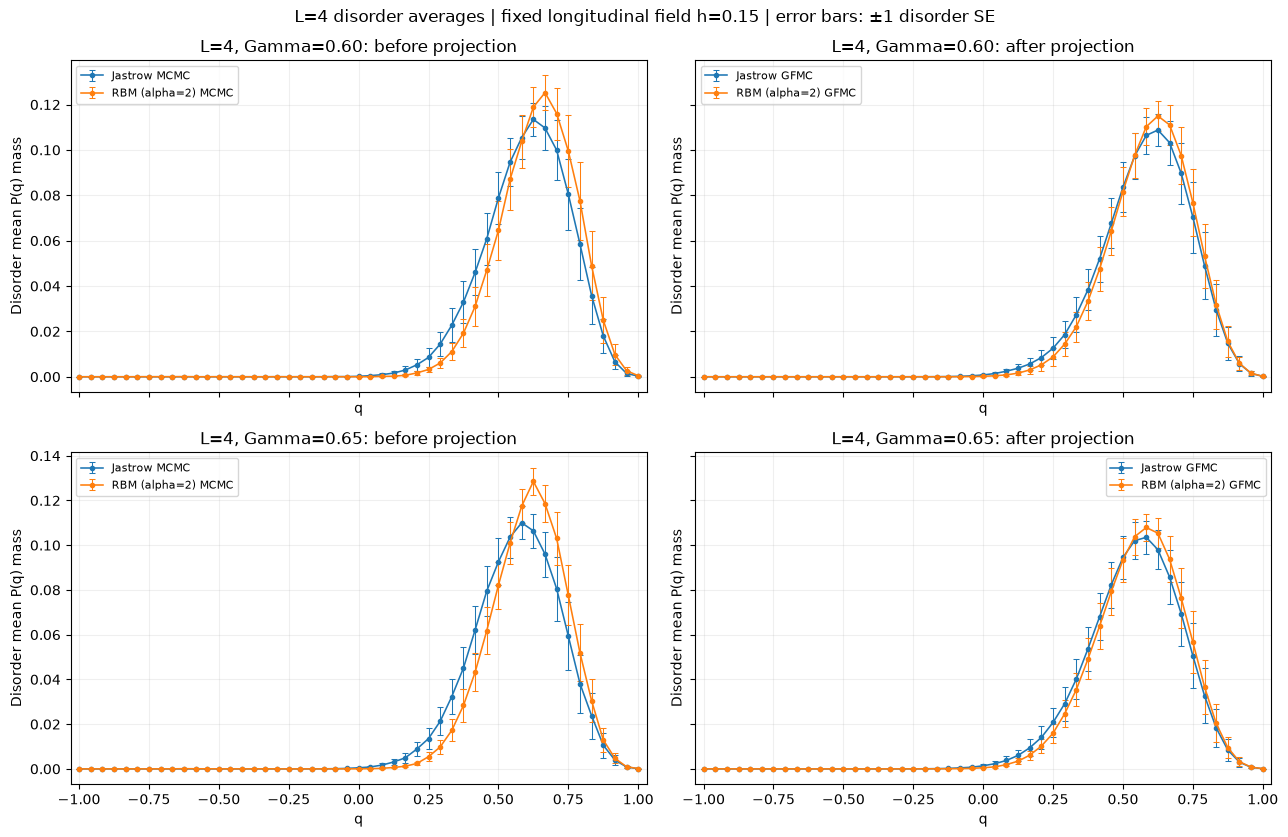

In [3]:
fig,axes=plt.subplots(2,2,figsize=(13,8.5),sharex=True,sharey='row')
for row,g in enumerate([.6,.65]):
    for kind in ['jastrow','rbm_2']:
        grid,values=guide_group(guides,4,g,kind)
        curve(axes[row,0],grid,values,names[kind]+' MCMC',colors[kind])
        grid,values=projected_group(4,g,kind)
        curve(axes[row,1],grid,values,names[kind]+' GFMC',colors[kind])
    axes[row,0].set_title(f'L=4, Gamma={g:.2f}: before projection')
    axes[row,1].set_title(f'L=4, Gamma={g:.2f}: after projection')
axes_style(axes)
fig.suptitle('L=4 disorder averages | fixed longitudinal field h=0.15 | error bars: ±1 disorder SE',fontsize=12)
finish(fig,'disorder_mean_l4_before_after')


In [4]:
# Integrity checks and a compact numerical audit; no individual-disorder plots.
for r in projected+l2+guides:
    assert hashlib.sha256((folder/r['raw_file']).read_bytes()).hexdigest()==r['raw_sha256']
for r in projected:
    p=np.array(r['mass']); q=np.array(r['q_grid'])
    assert np.all(p>=0) and np.isclose(p.sum(),1)
    np.testing.assert_allclose([q@p,q**2@p],[r['q'],r['q2']],atol=1e-12)
rows=[]
for L in [2,4]:
    for g in [.6,.65]:
        for kind in ['jastrow','rbm_2']:
            q,p=projected_group(L,g,kind)
            if q is None:
                continue
            rs=[r for r in projected if (r['task']['L'],r['task']['gamma'],r['task']['kind'])==(L,g,kind)]
            mean=p.mean(0)
            sample_means=p@q
            within_variance=float(np.mean(p@(q*q)-sample_means**2))
            between_variance=float(np.var(sample_means))
            np.testing.assert_allclose(within_variance+between_variance,q**2@mean-(q@mean)**2,atol=1e-12)
            magnetizations=[]
            for r in rs:
                with np.load(folder/r['raw_file']) as data:
                    spin_mean=data['tags'].mean(3)
                    magnetizations.append(float((data['counts']/r['task']['walkers']*spin_mean).sum(2).mean()))
            tv='—'
            if L==2:
                truth=np.mean([r['exact']['pq'] for r in exact if r['gamma']==g and r['sample_id'] in range(50000,50008)],axis=0)
                tv=f'{np.abs(mean-truth).sum()/2:.4f}'
            rows.append([L,g,names[kind],f'{q@mean:.5f}',f'{np.sqrt(q**2@mean-(q@mean)**2):.4f}',
                         f'{within_variance:.5f}',f'{between_variance:.5f}',
                         f'{np.mean(magnetizations):.4f}',f'{mean[q<0].sum():.5f}',
                         tv,f"{sum(r['ancestry_alarm'] for r in rs)}/16"])
headers=['L','Gamma','Guide','Projected mean q','Width sigma(q)','Within-disorder variance','Between-disorder variance','Uniform m','P(q<0)','TV to exact mean','Ancestry alarms']
display(Markdown('| '+' | '.join(headers)+' |\n| '+' | '.join(['---']*len(headers))+' |\n'+
    '\n'.join('| '+' | '.join(map(str,row))+' |' for row in rows)))
print('Raw histogram hashes and moment identities verified. Data:',folder)


| L | Gamma | Guide | Projected mean q | Width sigma(q) | Within-disorder variance | Between-disorder variance | Uniform m | P(q<0) | TV to exact mean | Ancestry alarms |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 2 | 0.6 | Jastrow | 0.48912 | 0.3651 | 0.09757 | 0.03573 | 0.1059 | 0.07987 | 0.0090 | 2/16 |
| 2 | 0.6 | RBM (alpha=2) | 0.47827 | 0.3759 | 0.10495 | 0.03639 | 0.1060 | 0.08860 | 0.0009 | 0/16 |
| 2 | 0.65 | Jastrow | 0.42855 | 0.3882 | 0.11061 | 0.04012 | 0.0976 | 0.11108 | 0.0080 | 2/16 |
| 2 | 0.65 | RBM (alpha=2) | 0.42041 | 0.3969 | 0.11863 | 0.03889 | 0.0972 | 0.11848 | 0.0013 | 0/16 |
| 4 | 0.6 | Jastrow | 0.58095 | 0.1567 | 0.01914 | 0.00542 | 0.0690 | 0.00074 | — | 6/16 |
| 4 | 0.6 | RBM (alpha=2) | 0.59730 | 0.1453 | 0.01690 | 0.00421 | 0.0677 | 0.00014 | — | 8/16 |
| 4 | 0.65 | Jastrow | 0.53933 | 0.1625 | 0.02040 | 0.00600 | 0.0660 | 0.00160 | — | 5/16 |
| 4 | 0.65 | RBM (alpha=2) | 0.55709 | 0.1532 | 0.01927 | 0.00421 | 0.0642 | 0.00043 | — | 14/16 |

Raw histogram hashes and moment identities verified. Data: /root/autodl-tmp/disorder-scaling-20261103-v1/preliminary_notebook_bundle/data/kagome/ltfim_disorder_scaling_v1/notebook_snapshot/20261103T031619Z_compact_complete


All disorder samples, seeds, starts, repeats and ancestry alarms remain
in the accompanying data. Alarmed runs retain equal disorder weight. Projection
results remain preliminary: agreement with $L=2$ exact data does not qualify
$L=4$ population or forward-time convergence. Complete matched $L=6$ histograms
are not yet available in this snapshot. No crossing or collapse is inferred.